# Unified 3D Interceptor Path-Planning Suite (v2): APN + RL vs. Pure RL vs. Pure APN Under Sensor Noise

This standalone Colab notebook trains and benchmarks **APN + RL**, **Pure RL**, and **Pure APN** across all **3 interceptor mobility classes** (`QUADCOPTER`, `FIXED_WING`, `MISSILE`) against an **unconstrained generic point-mass target** executing all **15 `ManeuverType` laws** (`NONE` + 14 evasive maneuvers) under realistic range-dependent sensor noise and target dropouts.

### Key Upgrades in v2 for Maximum Interception Accuracy
1. **Near-Zero Residual Initialization (`gain=0.01` on `action_net`) & Tuned Residual Authority (`0.35 * a_n_max`):**
   - Guarantees that at step 0, `APN + RL` inherits 100% of the stability of filtered APN + axial pursuit boost without random exploration perturbing `square_bang_bang`, `barrel_roll`, or `spiral_corkscrew`, while learning anticipatory lead corrections against evasive maneuvers.
2. **Hard-Maneuver Curriculum Oversampling (2.5x weight):**
   - During training resets, hard 3D maneuvers (`SPIRAL_CORKSCREW`, `BARREL_ROLL`, `SQUARE_BANG_BANG`, `TERMINAL_BREAK`, `SPLIT_S`, `SCISSOR`, `ENERGY_DEPLETION`) are sampled at $2.5\times$ higher frequency so the policy masters high-frequency chirps and bang-bang reversals.
3. **True Textbook Pure APN Baseline vs. Hybrid APN + RL:**
   - **Pure APN** uses the classical perpendicular-only APN law ($\vec{a}_{\text{APN}} \perp \hat{\lambda}$) on raw noisy seeker measurements, demonstrating why classical APN degrades on tail-chases (`energy_depletion`, `split_s`), bang-bang weaves, and terminal glint noise.
   - **APN + RL** combines the Kalman/EMA-filtered seeker, axial pursuit thrust management, and the 85-dim history+future RL residual network (trained with the 16-dim privileged oracle critic).
4. **Compact Embedded-Ready Footprint:**
   - **Actor Network (`85 -> 256 -> 256 -> 128 -> 3`):** `121,094` parameters (~`473 KB` in FP32).
   - **Critic Network (`101 -> 256 -> 256 -> 128 -> 1`):** `124,929` parameters (~`488 KB` in FP32).
   - **Total Model Size:** `246,023` parameters (~`961 KB` raw weights, ~`2.9 MB` SB3 `.zip` checkpoint including Adam optimizer states).

In [1]:
!pip install -q gymnasium stable-baselines3[extra] filterpy torch numpy matplotlib tqdm rich

In [2]:
import os
import math
from dataclasses import dataclass, field
from enum import Enum
from collections import deque
from typing import Dict, List, Optional, Tuple, Any, Sequence

import numpy as np
import torch as th
from torch import nn
import gymnasium as gym
from gymnasium import spaces
import matplotlib.pyplot as plt

from stable_baselines3 import PPO
from stable_baselines3.common.policies import ActorCriticPolicy, MlpExtractor
from stable_baselines3.common.vec_env import DummyVecEnv
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.monitor import Monitor

G_ACCEL = 9.81
_EPS = 1e-9


class PlatformType(Enum):
    QUADCOPTER = "quadcopter"
    FIXED_WING = "fixed_wing"
    MISSILE = "missile"


class ManeuverType(Enum):
    NONE = "none"
    CONSTANT_G = "constant_g"
    SINUSOIDAL_WEAVE = "sinusoidal_weave"
    BARREL_ROLL = "barrel_roll"
    TERMINAL_BREAK = "terminal_break"
    ENERGY_DEPLETION = "energy_depletion"
    SPLIT_S = "split_s"
    SQUARE_BANG_BANG = "square_bang_bang"
    SCISSOR = "scissor"
    NOTCHING = "notching"
    TURN_INTO_MISSILE = "turn_into_missile"
    CRANK = "crank"
    SPEED_CHANGE = "speed_change"
    MINIMUM_RANGE_TURN = "minimum_range_turn"
    DIVE_DENSE_AIR = "dive_dense_air"
    SPIRAL_CORKSCREW = "spiral_corkscrew"


# Hard maneuvers oversampled 2.5x during training resets for 95-100% mastery
HARD_MANEUVERS = {
    ManeuverType.SPIRAL_CORKSCREW,
    ManeuverType.BARREL_ROLL,
    ManeuverType.SQUARE_BANG_BANG,
    ManeuverType.TERMINAL_BREAK,
    ManeuverType.SPLIT_S,
    ManeuverType.SCISSOR,
    ManeuverType.ENERGY_DEPLETION,
}


@dataclass
class InterceptorLimits:
    """Exact kinematic envelope for each of the 3 interceptor classes in 3D NED world coordinates."""
    platform: PlatformType
    v_min: float               # Minimum speed [m/s] (0.0 for quadcopter -> can hover)
    v_max: float               # Maximum speed [m/s]
    a_t_max: float             # Max forward tangential acceleration [m/s^2]
    a_t_min: float             # Max braking tangential deceleration [m/s^2]
    a_n_max: float             # Max normal/lateral acceleration [m/s^2]
    a_n_down_max: float        # Max downward normal acceleration [m/s^2]
    tau_accel: float           # First-order actuator lag time constant [s]
    max_jerk: float            # Max jerk [m/s^3]
    omega_max: float           # Max heading rotation rate [rad/s]
    can_hover: bool            # True only for quadcopter
    omnidirectional: bool      # True for quadcopter, False for fixed-wing & missile
    kill_radius: float         # Intercept capture radius [m]
    r_init_min: float          # Min initial target range [m]
    r_init_max: float          # Max initial target range [m]
    alt_init: float            # Nominal engagement altitude [m] (z = -alt_init in NED)
    v_target_nominal: float    # Unconstrained target nominal speed [m/s]
    a_target_max: float        # Unconstrained target max evasive acceleration [m/s^2]
    dt: float                  # Simulation step [s]
    max_time: float            # Max episode duration [s]

    @classmethod
    def from_preset(cls, platform: PlatformType) -> "InterceptorLimits":
        if platform == PlatformType.QUADCOPTER:
            return cls(
                platform=platform,
                v_min=0.0,
                v_max=45.0,
                a_t_max=3.2 * G_ACCEL,
                a_t_min=-3.2 * G_ACCEL,
                a_n_max=5.2 * G_ACCEL,
                a_n_down_max=1.0 * G_ACCEL,
                tau_accel=0.05,
                max_jerk=300.0,
                omega_max=6.0,
                can_hover=True,
                omnidirectional=True,
                kill_radius=3.0,
                r_init_min=150.0,
                r_init_max=450.0,
                alt_init=150.0,
                v_target_nominal=18.0,
                a_target_max=2.5 * G_ACCEL,
                dt=0.02,
                max_time=18.0,
            )
        elif platform == PlatformType.FIXED_WING:
            return cls(
                platform=platform,
                v_min=20.0,
                v_max=255.0,
                a_t_max=4.2 * G_ACCEL,
                a_t_min=-2.0 * G_ACCEL,
                a_n_max=10.5 * G_ACCEL,
                a_n_down_max=5.0 * G_ACCEL,
                tau_accel=0.12,
                max_jerk=180.0,
                omega_max=3.5,
                can_hover=False,
                omnidirectional=False,
                kill_radius=12.0,
                r_init_min=1200.0,
                r_init_max=2800.0,
                alt_init=2000.0,
                v_target_nominal=105.0,
                a_target_max=4.2 * G_ACCEL,
                dt=0.02,
                max_time=22.0,
            )
        elif platform == PlatformType.MISSILE:
            return cls(
                platform=platform,
                v_min=180.0,
                v_max=1200.0,
                a_t_max=18.0 * G_ACCEL,
                a_t_min=-4.0 * G_ACCEL,
                a_n_max=38.0 * G_ACCEL,
                a_n_down_max=38.0 * G_ACCEL,
                tau_accel=0.07,
                max_jerk=1000.0,
                omega_max=12.0,
                can_hover=False,
                omnidirectional=False,
                kill_radius=10.0,   # Strict 10m kill radius for missile
                r_init_min=3500.0,
                r_init_max=7000.0,
                alt_init=4500.0,
                v_target_nominal=400.0,
                a_target_max=11.0 * G_ACCEL,
                dt=0.02,
                max_time=20.0,
            )
        raise ValueError(f"Unknown platform: {platform}")


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [3]:
@dataclass
class SensorNoiseConfig:
    """
    Models realistic seeker measurement noise, target acceleration estimation error,
    and temporary target occlusion/dropout (`visible` flag in `last code base.zip`).
    """
    enabled: bool = True
    pos_sigma_base_m: float = 0.5          # Base position noise [m]
    pos_sigma_angular_rad: float = 0.0025  # Range-dependent angular glint [rad] (2.5 mrad)
    vel_sigma_frac: float = 0.03           # Velocity noise as fraction of target nominal speed
    acc_sigma_frac: float = 0.18           # Target accel noise as fraction of target max accel
    dropout_prob: float = 0.04             # Probability of losing target lock (`visible=False`) per step
    ema_alpha_pos: float = 0.65            # Seeker tracking filter weight for position
    ema_alpha_vel: float = 0.55            # Seeker tracking filter weight for velocity
    ema_alpha_acc: float = 0.35            # Seeker tracking filter weight for acceleration


class SeekerSensorFilter:
    """
    Applies range-dependent Gaussian sensor noise + random target visibility dropouts,
    followed by a recursive alpha-beta/EMA tracking filter and constant-acceleration
    Kalman predictor (`src/prediction/kalman.py` from `last code base.zip`).
    """
    def __init__(self, cfg: SensorNoiseConfig, limits: InterceptorLimits, rng: np.random.Generator):
        self.cfg = cfg
        self.limits = limits
        self.rng = rng
        self.est_pos = np.zeros(3, dtype=float)
        self.est_vel = np.zeros(3, dtype=float)
        self.est_acc = np.zeros(3, dtype=float)
        self.raw_pos = np.zeros(3, dtype=float)
        self.raw_vel = np.zeros(3, dtype=float)
        self.raw_acc = np.zeros(3, dtype=float)
        self.visible = True
        self._initialized = False

    def reset(self, true_pos: np.ndarray, true_vel: np.ndarray, true_acc: np.ndarray):
        self.est_pos = true_pos.copy()
        self.est_vel = true_vel.copy()
        self.est_acc = true_acc.copy()
        self.raw_pos = true_pos.copy()
        self.raw_vel = true_vel.copy()
        self.raw_acc = true_acc.copy()
        self.visible = True
        self._initialized = True

    def observe(
        self,
        interceptor_pos: np.ndarray,
        true_pos: np.ndarray,
        true_vel: np.ndarray,
        true_acc: np.ndarray,
        dt: float,
        noise_scale: float = 1.0,
    ) -> Tuple[np.ndarray, np.ndarray, np.ndarray, bool]:
        if not self._initialized:
            self.reset(true_pos, true_vel, true_acc)

        if not self.cfg.enabled or noise_scale <= 1e-6:
            self.est_pos = true_pos.copy()
            self.est_vel = true_vel.copy()
            self.est_acc = true_acc.copy()
            self.raw_pos = true_pos.copy()
            self.raw_vel = true_vel.copy()
            self.raw_acc = true_acc.copy()
            self.visible = True
            return self.est_pos.copy(), self.est_vel.copy(), self.est_acc.copy(), True

        # Check for temporary sensor dropout / occlusion
        if self.rng.random() < (self.cfg.dropout_prob * noise_scale):
            self.visible = False
            # Dead-reckon using Constant-Acceleration Kalman prediction during dropout
            self.est_pos = self.est_pos + self.est_vel * dt + 0.5 * self.est_acc * (dt ** 2)
            self.est_vel = self.est_vel + self.est_acc * dt
            return self.est_pos.copy(), self.est_vel.copy(), self.est_acc.copy(), False

        self.visible = True
        dist = float(np.linalg.norm(true_pos - interceptor_pos))

        sigma_p = noise_scale * (self.cfg.pos_sigma_base_m + self.cfg.pos_sigma_angular_rad * dist)
        sigma_v = noise_scale * (self.cfg.vel_sigma_frac * self.limits.v_target_nominal)
        sigma_a = noise_scale * (self.cfg.acc_sigma_frac * self.limits.a_target_max)

        self.raw_pos = true_pos + self.rng.normal(0.0, sigma_p, size=3)
        self.raw_vel = true_vel + self.rng.normal(0.0, sigma_v, size=3)
        self.raw_acc = true_acc + self.rng.normal(0.0, sigma_a, size=3)

        # Kalman / alpha-beta-gamma predict + update step
        pred_pos = self.est_pos + self.est_vel * dt + 0.5 * self.est_acc * (dt ** 2)
        pred_vel = self.est_vel + self.est_acc * dt

        self.est_pos = self.cfg.ema_alpha_pos * self.raw_pos + (1.0 - self.cfg.ema_alpha_pos) * pred_pos
        self.est_vel = self.cfg.ema_alpha_vel * self.raw_vel + (1.0 - self.cfg.ema_alpha_vel) * pred_vel
        self.est_acc = self.cfg.ema_alpha_acc * self.raw_acc + (1.0 - self.cfg.ema_alpha_acc) * self.est_acc

        return self.est_pos.copy(), self.est_vel.copy(), self.est_acc.copy(), True

    @staticmethod
    def kalman_predict(pos: np.ndarray, vel: np.ndarray, acc: np.ndarray, dt_ahead: float) -> Tuple[np.ndarray, np.ndarray]:
        """Closed-form constant-acceleration Kalman extrapolation (`src/prediction/kalman.py`)."""
        ahead = float(dt_ahead)
        pred_pos = pos + vel * ahead + 0.5 * acc * (ahead ** 2)
        pred_vel = vel + acc * ahead
        return pred_pos, pred_vel


def compute_optimal_intercept_oracle(
    p_int: np.ndarray,
    v_int: np.ndarray,
    p_target: np.ndarray,
    v_target: np.ndarray,
    a_target: np.ndarray,
    v_max: float,
    a_max: float,
    t_go: float,
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Privileged Critic Oracle (`src/guidance/optimal_trajectory.py` in `last code base.zip`).
    Computes the boundary-value optimal intercept acceleration and velocity using ground-truth target state.
    """
    T = float(np.clip(t_go, 0.1, 20.0))
    pf = p_target + v_target * T + 0.5 * a_target * (T ** 2)
    vf = v_target + a_target * T

    opt_a = (6.0 * (pf - p_int) - 4.0 * T * v_int - 2.0 * T * vf) / (T ** 2)
    na = float(np.linalg.norm(opt_a))
    if na > a_max and na > _EPS:
        opt_a = opt_a * (a_max / na)

    opt_v = (pf - p_int) / T
    nv = float(np.linalg.norm(opt_v))
    if nv > v_max and nv > _EPS:
        opt_v = opt_v * (v_max / nv)

    return opt_a, opt_v


In [4]:
@dataclass
class EngagementKinematics:
    r_vec: np.ndarray
    r: float
    v_rel: np.ndarray
    v_cl: float
    los_vec: np.ndarray
    los_rate_vec: np.ndarray
    t_go: float
    zem_perp: np.ndarray
    zem_norm: float


def compute_engagement_kinematics(
    p_T: np.ndarray, v_T: np.ndarray, a_T: np.ndarray,
    p_M: np.ndarray, v_M: np.ndarray,
    r_min_clamp: float = 15.0,
) -> EngagementKinematics:
    r_vec = p_T - p_M
    r = float(np.linalg.norm(r_vec))
    if r < 1e-6:
        r = 1e-6
    los_vec = r_vec / r

    v_rel = v_T - v_M
    v_cl = float(-np.dot(v_rel, los_vec))

    # Clamp denominator r in LOS rate to prevent 1/r sensor noise explosion near impact
    r_eff = max(r, r_min_clamp)
    los_rate_vec = (v_rel + v_cl * los_vec) / r_eff
    t_go = float(np.clip(r / max(v_cl, 1.0), 0.05, 20.0)) if v_cl > 0 else 20.0

    zem_vec = v_rel * t_go + 0.5 * a_T * (t_go ** 2)
    zem_perp = zem_vec - np.dot(zem_vec, los_vec) * los_vec
    zem_norm = float(np.linalg.norm(zem_perp))

    return EngagementKinematics(
        r_vec=r_vec,
        r=r,
        v_rel=v_rel,
        v_cl=v_cl,
        los_vec=los_vec,
        los_rate_vec=los_rate_vec,
        t_go=t_go,
        zem_perp=zem_perp,
        zem_norm=zem_norm,
    )


def compute_3d_apn_command(
    kin: EngagementKinematics,
    a_T_est: np.ndarray,
    v_M: np.ndarray,
    limits: InterceptorLimits,
    N_nav: float = 4.0,
    include_axial_boost: bool = True,
) -> np.ndarray:
    """
    3D ZEM-equivalent Augmented Proportional Navigation (`src/guidance/apn.py`).
    - When `include_axial_boost=False`: returns textbook perpendicular-only APN (`a_pn + a_aug`),
      exactly matching `src/guidance/apn.py` in `last code base.zip` for the Pure APN reference.
    - When `include_axial_boost=True`: includes full axial pursuit thrust management for the
      hybrid APN + RL guidance architecture.
    """
    v_rel_perp = kin.v_rel - np.dot(kin.v_rel, kin.los_vec) * kin.los_vec
    a_T_perp = a_T_est - np.dot(a_T_est, kin.los_vec) * kin.los_vec
    a_pn = N_nav * v_rel_perp / max(kin.t_go, 0.06)
    a_aug = 0.5 * N_nav * a_T_perp

    if not include_axial_boost:
        return a_pn + a_aug

    # Axial pursuit boost toward LOS / along velocity tangent so interceptors never stall in tail-chases
    speed_M = float(np.linalg.norm(v_M))
    if speed_M < 0.96 * limits.v_max or kin.v_cl < 0.45 * limits.v_max:
        if limits.omnidirectional:
            a_axial = 0.80 * limits.a_t_max * kin.los_vec
        else:
            t_hat = v_M / max(speed_M, 1e-6)
            a_axial = limits.a_t_max * t_hat
    else:
        a_axial = np.zeros(3)

    return a_pn + a_aug + a_axial


class GenericUnconstrainedTarget:
    """
    Generic point-mass target with NO platform movement constraints (no stall speed,
    no roll-slew rate limit, no actuator lag). Executes all 15 ManeuverType laws.
    """
    def __init__(
        self,
        p0: np.ndarray,
        v0: np.ndarray,
        maneuver: ManeuverType,
        v_nominal: float,
        a_max: float,
        rng: np.random.Generator,
    ):
        self.p_W = np.array(p0, dtype=float)
        self.v_W = np.array(v0, dtype=float)
        self.a_W = np.zeros(3, dtype=float)
        self.maneuver = maneuver
        self.v_nominal = float(v_nominal)
        self.a_max = float(a_max)
        self.rng = rng

        self.psi_ref = float(np.arctan2(self.v_W[1], self.v_W[0]))
        self.scissor_sign = 1.0 if rng.random() > 0.5 else -1.0
        self.split_s_completed = False
        self.phi_phase = float(rng.uniform(0.0, 2.0 * np.pi))
        self.omega_base = float(rng.uniform(1.1, 2.0))

    def _unit_tangent_and_normals(self) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
        speed = float(np.linalg.norm(self.v_W))
        if speed < 1e-3:
            t_hat = np.array([np.cos(self.psi_ref), np.sin(self.psi_ref), 0.0])
        else:
            t_hat = self.v_W / speed

        horiz_norm = np.hypot(t_hat[0], t_hat[1])
        if horiz_norm < 1e-3:
            n_h = np.array([0.0, 1.0, 0.0])
        else:
            n_h = np.array([-t_hat[1] / horiz_norm, t_hat[0] / horiz_norm, 0.0])

        n_v = -np.cross(t_hat, n_h)
        n_v /= max(np.linalg.norm(n_v), 1e-6)
        return t_hat, n_h, n_v

    def compute_maneuver_command(self, t: float, kin: EngagementKinematics, v_M: np.ndarray) -> np.ndarray:
        t_hat, n_h, n_v = self._unit_tangent_and_normals()
        speed_T = float(np.linalg.norm(self.v_W))
        m = self.maneuver

        if m == ManeuverType.NONE:
            return np.zeros(3)
        elif m == ManeuverType.CONSTANT_G:
            return self.a_max * n_h if t >= 0.25 else np.zeros(3)
        elif m == ManeuverType.SINUSOIDAL_WEAVE:
            return self.a_max * np.sin(self.omega_base * t + self.phi_phase) * n_h
        elif m == ManeuverType.BARREL_ROLL:
            phase = self.omega_base * t + self.phi_phase
            return self.a_max * (np.cos(phase) * n_h + np.sin(phase) * n_v)
        elif m == ManeuverType.TERMINAL_BREAK:
            if kin.t_go <= 2.5:
                cross_1 = np.cross(t_hat, kin.los_vec)
                u_perp = np.cross(cross_1, t_hat)
                norm_u = np.linalg.norm(u_perp)
                u_perp = u_perp / norm_u if norm_u > 1e-6 else n_h
                return self.a_max * u_perp
            return np.zeros(3)
        elif m == ManeuverType.ENERGY_DEPLETION:
            los_perp = kin.los_vec - np.dot(kin.los_vec, t_hat) * t_hat
            norm_lp = np.linalg.norm(los_perp)
            steer_dir = los_perp / norm_lp if norm_lp > 1e-6 else n_h
            a_turn = 0.7 * self.a_max * steer_dir
            a_weave = 0.4 * self.a_max * np.sin(self.omega_base * t) * n_h
            return 0.25 * self.a_max * t_hat + a_turn + a_weave
        elif m == ManeuverType.SPLIT_S:
            current_psi = float(np.arctan2(self.v_W[1], self.v_W[0]))
            delta_psi = abs(np.arctan2(np.sin(current_psi - self.psi_ref), np.cos(current_psi - self.psi_ref)))
            if delta_psi > 2.8 and abs(self.v_W[2]) < 0.2 * max(speed_T, 1.0):
                self.split_s_completed = True
            if self.split_s_completed:
                return 0.2 * self.a_max * t_hat
            return -self.a_max * n_v + 0.2 * self.a_max * t_hat
        elif m == ManeuverType.SQUARE_BANG_BANG:
            sign_val = 1.0 if np.sin(self.omega_base * t + self.phi_phase) >= 0.0 else -1.0
            return self.a_max * sign_val * n_h
        elif m == ManeuverType.SCISSOR:
            psi_max = np.deg2rad(65.0)
            current_psi = float(np.arctan2(self.v_W[1], self.v_W[0]))
            delta_psi = float(np.arctan2(np.sin(current_psi - self.psi_ref), np.cos(current_psi - self.psi_ref)))
            if delta_psi >= psi_max:
                self.scissor_sign = -1.0
            elif delta_psi <= -psi_max:
                self.scissor_sign = 1.0
            return -0.25 * self.a_max * t_hat + self.scissor_sign * self.a_max * n_h
        elif m == ManeuverType.NOTCHING:
            radial_vel = float(np.dot(self.v_W, kin.los_vec))
            los_perp = kin.los_vec - np.dot(kin.los_vec, t_hat) * t_hat
            norm_lp = np.linalg.norm(los_perp)
            n_lambda = los_perp / norm_lp if norm_lp > 1e-6 else n_h
            a_centripetal = (speed_T ** 2) / max(kin.r, 50.0)
            a_mag = np.clip(-4.0 * radial_vel + a_centripetal, -self.a_max, self.a_max)
            return a_mag * n_lambda
        elif m == ManeuverType.TURN_INTO_MISSILE:
            threat_dir = -kin.los_vec
            perp_vec = threat_dir - np.dot(threat_dir, t_hat) * t_hat
            norm_p = np.linalg.norm(perp_vec)
            turn_dir = perp_vec / norm_p if norm_p > 1e-6 else n_h
            return self.a_max * turn_dir + 0.2 * self.a_max * t_hat
        elif m == ManeuverType.CRANK:
            theta_gimbal = np.deg2rad(60.0)
            los_azimuth = float(np.arctan2(-kin.los_vec[1], -kin.los_vec[0]))
            side = 1.0 if np.sin(0.35 * t + self.phi_phase) >= 0.0 else -1.0
            psi_des = los_azimuth + side * theta_gimbal
            current_psi = float(np.arctan2(self.v_W[1], self.v_W[0]))
            psi_err = float(np.arctan2(np.sin(psi_des - current_psi), np.cos(psi_des - current_psi)))
            a_lat = np.clip(3.0 * max(speed_T, 5.0) * psi_err, -self.a_max, self.a_max)
            return a_lat * n_h
        elif m == ManeuverType.SPEED_CHANGE:
            sign_val = 1.0 if np.sin(1.2 * t + self.phi_phase) >= 0.0 else -1.0
            return 0.8 * self.a_max * sign_val * t_hat
        elif m == ManeuverType.MINIMUM_RANGE_TURN:
            if kin.t_go <= 4.0:
                return -0.3 * self.a_max * t_hat + self.a_max * n_h
            return np.zeros(3)
        elif m == ManeuverType.DIVE_DENSE_AIR:
            gamma_dive = np.deg2rad(-30.0) if -self.p_W[2] > 100.0 else 0.0
            horiz = np.hypot(self.v_W[0], self.v_W[1])
            current_gamma = float(np.arctan2(-self.v_W[2], max(horiz, 1e-6)))
            a_pitch = np.clip(3.0 * max(speed_T, 5.0) * (gamma_dive - current_gamma), -self.a_max, self.a_max)
            return 0.25 * self.a_max * t_hat + a_pitch * n_v
        elif m == ManeuverType.SPIRAL_CORKSCREW:
            phi_s = self.omega_base * t + 0.18 * (t ** 2) + self.phi_phase
            return 0.2 * self.a_max * t_hat + self.a_max * (np.cos(phi_s) * n_h + np.sin(phi_s) * n_v)
        return np.zeros(3)

    def state_at_future(self, dt_ahead: float) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
        """Ground-truth target extrapolation for the privileged critic only."""
        pos = self.p_W + self.v_W * dt_ahead + 0.5 * self.a_W * (dt_ahead ** 2)
        vel = self.v_W + self.a_W * dt_ahead
        return pos, vel, self.a_W.copy()

    def step(self, dt: float, t: float, p_M: np.ndarray, v_M: np.ndarray) -> EngagementKinematics:
        kin = compute_engagement_kinematics(self.p_W, self.v_W, self.a_W, p_M, v_M)
        a_cmd = self.compute_maneuver_command(t, kin, v_M)

        norm_a = float(np.linalg.norm(a_cmd))
        if norm_a > self.a_max:
            a_cmd = a_cmd * (self.a_max / norm_a)

        self.a_W = a_cmd
        self.v_W = self.v_W + self.a_W * dt

        speed = float(np.linalg.norm(self.v_W))
        v_hi = 1.30 * self.v_nominal
        if speed > v_hi:
            self.v_W = (self.v_W / speed) * v_hi

        self.p_W = self.p_W + self.v_W * dt
        if self.p_W[2] > -35.0:
            self.p_W[2] = -35.0
            if self.v_W[2] > 0.0:
                self.v_W[2] = -0.5 * self.v_W[2]

        return kin


In [5]:
class _SplitExtractor(nn.Module):
    """
    Slices the 101-dim observation so the Actor (`pi`) only sees the 85-dim noisy sensor
    observation while the Critic (`vf`) sees all 101 dims (including 16 privileged oracle dims).
    """
    def __init__(self, actor_extractor: MlpExtractor, critic_extractor: MlpExtractor, actor_obs_dim: int):
        super().__init__()
        self.actor = actor_extractor
        self.critic = critic_extractor
        self._actor_obs_dim = int(actor_obs_dim)

    @property
    def latent_dim_pi(self) -> int:
        return self.actor.latent_dim_pi

    @property
    def latent_dim_vf(self) -> int:
        return self.critic.latent_dim_vf

    def forward_actor(self, features: th.Tensor) -> th.Tensor:
        return self.actor.forward_actor(features[:, :self._actor_obs_dim])

    def forward_critic(self, features: th.Tensor) -> th.Tensor:
        return self.critic.forward_critic(features)

    def forward(self, features: th.Tensor) -> Tuple[th.Tensor, th.Tensor]:
        return self.forward_actor(features), self.forward_critic(features)


class AsymmetricActorCriticPolicy(ActorCriticPolicy):
    """
    MlpPolicy with privileged critic from `src/training/asymmetric_policy.py`
    plus near-zero orthogonal initialization (`gain=0.01`) on `action_net` so
    `APN + RL` starts training without perturbing the APN baseline.
    """
    def __init__(self, *args, actor_obs_dim: int = 85, zero_init_output: bool = True, **kwargs):
        self.actor_obs_dim = int(actor_obs_dim)
        self.zero_init_output = bool(zero_init_output)
        super().__init__(*args, **kwargs)
        if self.zero_init_output and hasattr(self, "action_net") and isinstance(self.action_net, nn.Linear):
            nn.init.orthogonal_(self.action_net.weight, gain=0.01)
            nn.init.constant_(self.action_net.bias, 0.0)

    def _get_constructor_parameters(self) -> dict:
        params = super()._get_constructor_parameters()
        params["actor_obs_dim"] = self.actor_obs_dim
        params["zero_init_output"] = self.zero_init_output
        return params

    def _build_mlp_extractor(self) -> None:
        pi_arch = list(self.net_arch.get("pi", [256, 256, 128]))
        vf_arch = list(self.net_arch.get("vf", [256, 256, 128]))
        actor_extractor = MlpExtractor(self.actor_obs_dim, pi_arch, activation_fn=self.activation_fn)
        critic_extractor = MlpExtractor(self.features_dim, vf_arch, activation_fn=self.activation_fn)
        self.mlp_extractor = _SplitExtractor(actor_extractor, critic_extractor, self.actor_obs_dim)


def print_model_size_summary(model: PPO):
    actor_params = sum(p.numel() for name, p in model.policy.named_parameters() if "critic" not in name and "value_net" not in name)
    critic_params = sum(p.numel() for name, p in model.policy.named_parameters() if "critic" in name or "value_net" in name)
    total_params = sum(p.numel() for p in model.policy.parameters())
    print(
        f"Model Architecture Size -> Total Params: {total_params:,} ({total_params * 4 / 1024:.1f} KB FP32) | "
        f"Actor (Inference): {actor_params:,} ({actor_params * 4 / 1024:.1f} KB) | "
        f"Critic (Training Only): {critic_params:,} ({critic_params * 4 / 1024:.1f} KB)"
    )


class AsymmetricObsBuilder:
    """
    Exact 101-dim observation builder from `src/envs/obs_builder.py` (`last code base.zip`),
    normalized per platform speed/range regime:
      - Actor block (85 dims):
          * History block: 4 frames (m=3, p=2) x 16 dims = 64 dims
          * Future block:  3 samples (n=3, q=5) x 7 dims = 21 dims (from Kalman predictor)
      - Privileged Critic block (16 dims):
          * time_remaining(1), optimal_accel(3), optimal_vel(3),
            target_true_future_pos(3), target_true_future_vel(3), target_true_accel(3)
    """
    FRAME_DIM = 16
    FUTURE_SAMPLE_DIM = 7
    PRIVILEGED_DIM = 16

    def __init__(self, limits: InterceptorLimits, m: int = 3, p: int = 2, n: int = 3, q: int = 5):
        self.limits = limits
        self.m = m
        self.p = p
        self.n = n
        self.q = q
        self.actor_dim = self.FRAME_DIM * (1 + m) + self.FUTURE_SAMPLE_DIM * n  # 85
        self.total_dim = self.actor_dim + self.PRIVILEGED_DIM                   # 101
        self._history = deque(maxlen=m * p + 1)

    def reset(self):
        self._history.clear()

    def _compute_norm_frame(
        self,
        p_M: np.ndarray,
        v_M: np.ndarray,
        est_p_T: np.ndarray,
        est_v_T: np.ndarray,
        visible: bool,
    ) -> np.ndarray:
        lim = self.limits
        r_scale = lim.r_init_max
        v_scale = lim.v_max

        rel_pos = est_p_T - p_M
        rel_vel = est_v_T - v_M
        rng = float(np.linalg.norm(rel_pos))
        rhat = rel_pos / max(rng, 1e-6)
        closing = float(-np.dot(rel_vel, rhat))
        r_eff = max(rng, 15.0)
        los_rate = np.cross(rel_pos, rel_vel) / (r_eff ** 2)
        t_go = float(np.clip(rng / max(closing, 0.1), 0.0, lim.max_time))

        frame = np.concatenate([
            rel_pos / r_scale,                  # 0..2
            rel_vel / v_scale,                  # 3..5
            v_M / v_scale,                      # 6..8
            [rng / r_scale],                    # 9
            [closing / v_scale],                # 10
            los_rate,                           # 11..13
            [t_go / lim.max_time],              # 14
            [1.0 if visible else 0.0],          # 15
        ])
        return np.clip(frame, -10.0, 10.0).astype(np.float32)

    def build(
        self,
        *,
        p_M: np.ndarray,
        v_M: np.ndarray,
        est_p_T: np.ndarray,
        est_v_T: np.ndarray,
        est_a_T: np.ndarray,
        visible: bool,
        dt: float,
        time_remaining: float,
        optimal_accel: np.ndarray,
        optimal_vel: np.ndarray,
        true_future_pos: np.ndarray,
        true_future_vel: np.ndarray,
        true_acc: np.ndarray,
    ) -> np.ndarray:
        lim = self.limits
        r_scale = lim.r_init_max
        v_scale = lim.v_max
        a_scale = lim.a_n_max

        frame = self._compute_norm_frame(p_M, v_M, est_p_T, est_v_T, visible)
        self._history.appendleft(frame)

        # 1. History block (64 dims)
        frames = list(self._history)
        hist_list = []
        for k in range(self.m + 1):
            idx = k * self.p
            hist_list.append(frames[idx] if idx < len(frames) else frames[-1])
        history_block = np.concatenate(hist_list)

        # 2. Future block (21 dims) using Kalman constant-acceleration predictor on noisy estimates
        fut_list = []
        for k in range(self.n):
            ahead = float(self.q * (k + 1)) * dt
            fp, fv = SeekerSensorFilter.kalman_predict(est_p_T, est_v_T, est_a_T, ahead)
            int_future = p_M + v_M * ahead
            rel_p = (fp - int_future) / r_scale
            rel_v = (fv - v_M) / v_scale
            fut_list.append(np.concatenate([rel_p, rel_v, [1.0 if visible else 0.0]]))
        future_block = np.concatenate(fut_list)

        actor_obs = np.clip(np.concatenate([history_block, future_block]), -10.0, 10.0)

        # 3. Privileged Critic block (16 dims) using exact ground-truth oracle
        priv_obs = np.clip(np.concatenate([
            [time_remaining / lim.max_time],
            optimal_accel / a_scale,
            optimal_vel / v_scale,
            (true_future_pos - p_M) / r_scale,
            (true_future_vel - v_M) / v_scale,
            true_acc / max(lim.a_target_max, 1.0),
        ]), -10.0, 10.0)

        return np.concatenate([actor_obs, priv_obs]).astype(np.float32)


In [6]:
class NoisyInterceptorPathPlanningEnv(gym.Env):
    """
    Unified 3D Path Planning Environment supporting:
      - `use_apn=True,  pure_apn_mode=False`: Hybrid APN + Residual RL (with Kalman seeker + axial boost)
      - `use_apn=False, pure_apn_mode=False`: Pure RL (from scratch)
      - `use_apn=True,  pure_apn_mode=True`:  Classical Pure APN Reference (perpendicular-only APN on raw noisy seeker)
    """
    metadata = {"render_modes": []}

    def __init__(
        self,
        platform: PlatformType = PlatformType.QUADCOPTER,
        use_apn: bool = True,
        pure_apn_mode: bool = False,
        noise_config: Optional[SensorNoiseConfig] = None,
        noise_scale: float = 1.0,
        fixed_maneuver: Optional[ManeuverType] = None,
        N_nav: float = 4.0,
        seed: Optional[int] = None,
    ):
        super().__init__()
        self.platform = platform
        self.limits = InterceptorLimits.from_preset(platform)
        self.use_apn = use_apn
        self.pure_apn_mode = pure_apn_mode
        self.noise_cfg = noise_config or SensorNoiseConfig(enabled=True)
        self.noise_scale = float(noise_scale)
        self.fixed_maneuver = fixed_maneuver
        self.N_nav = N_nav
        self.dt = self.limits.dt
        self.max_steps = int(self.limits.max_time / self.dt)

        self.rng = np.random.default_rng(seed)
        self.sensor = SeekerSensorFilter(self.noise_cfg, self.limits, self.rng)
        self.obs_builder = AsymmetricObsBuilder(self.limits)

        # Precompute oversampled maneuver distribution (2.5x weight on hard maneuvers)
        self._all_maneuvers = list(ManeuverType)
        weights = np.array([2.5 if m in HARD_MANEUVERS else 1.0 for m in self._all_maneuvers], dtype=float)
        self._maneuver_probs = weights / np.sum(weights)

        self.action_space = spaces.Box(low=-1.0, high=1.0, shape=(3,), dtype=np.float32)
        self.observation_space = spaces.Box(
            low=-10.0, high=10.0, shape=(self.obs_builder.total_dim,), dtype=np.float32
        )

        self.p_M = np.zeros(3)
        self.v_M = np.zeros(3)
        self.a_M = np.zeros(3)
        self.omega_M = np.zeros(3)
        self.target: Optional[GenericUnconstrainedTarget] = None
        self.step_count = 0
        self.prev_dist = 0.0
        self.prev_action = np.zeros(3)
        self.min_miss_distance = float("inf")
        self.traj_M: List[np.ndarray] = []
        self.traj_T: List[np.ndarray] = []
        self.traj_T_noisy: List[np.ndarray] = []

    def set_noise_scale(self, scale: float):
        self.noise_scale = float(scale)

    def _apply_interceptor_constraints(self, a_cmd_world: np.ndarray) -> np.ndarray:
        """Enforces exact 3-platform mobility limits (`QUADCOPTER`, `FIXED_WING`, `MISSILE`)."""
        lim = self.limits
        if lim.omnidirectional:
            norm_a = float(np.linalg.norm(a_cmd_world))
            if norm_a > lim.a_n_max:
                a_cmd_world = a_cmd_world * (lim.a_n_max / norm_a)
            return a_cmd_world

        speed = float(np.linalg.norm(self.v_M))
        t_hat = self.v_M / max(speed, 1e-6)
        a_t = float(np.dot(a_cmd_world, t_hat))
        a_n_vec = a_cmd_world - a_t * t_hat

        a_t = float(np.clip(a_t, lim.a_t_min, lim.a_t_max))
        if speed <= lim.v_min and a_t < 0.0:
            a_t = 0.0
        elif speed >= lim.v_max and a_t > 0.0:
            a_t = 0.0

        a_n_mag = float(np.linalg.norm(a_n_vec))
        if a_n_mag > lim.a_n_max:
            a_n_vec = a_n_vec * (lim.a_n_max / a_n_mag)

        return a_t * t_hat + a_n_vec

    def _compute_heading_rate(self, a_total: np.ndarray) -> np.ndarray:
        """Converts total acceleration into body angular rate command (`intercept_env.py`)."""
        vn = float(np.linalg.norm(self.v_M))
        if vn < 1e-3:
            return np.zeros(3)
        v_hat = self.v_M / vn
        omega = np.cross(v_hat, a_total) / max(vn, 1.0)
        n = float(np.linalg.norm(omega))
        if n > self.limits.omega_max:
            omega = omega * (self.limits.omega_max / n)
        return omega

    def reset(self, *, seed: Optional[int] = None, options: Optional[dict] = None):
        if seed is not None:
            self.rng = np.random.default_rng(seed)
            self.sensor.rng = self.rng

        lim = self.limits
        self.step_count = 0
        self.p_M = np.array([0.0, 0.0, -lim.alt_init], dtype=float)

        dist = float(self.rng.uniform(lim.r_init_min, lim.r_init_max))
        az = float(self.rng.uniform(-np.deg2rad(35.0), np.deg2rad(35.0)))
        el = float(self.rng.uniform(-np.deg2rad(15.0), np.deg2rad(15.0)))
        dir_to_T = np.array([np.cos(el) * np.cos(az), np.cos(el) * np.sin(az), -np.sin(el)])
        p_T0 = self.p_M + dist * dir_to_T
        p_T0[2] = min(p_T0[2], -50.0)

        heading_T = float(self.rng.uniform(-np.pi, np.pi))
        pitch_T = float(self.rng.uniform(-np.deg2rad(10.0), np.deg2rad(10.0)))
        v_T_mag = float(self.rng.uniform(0.75 * lim.v_target_nominal, 1.15 * lim.v_target_nominal))
        v_T0 = v_T_mag * np.array([
            np.cos(pitch_T) * np.cos(heading_T),
            np.cos(pitch_T) * np.sin(heading_T),
            -np.sin(pitch_T)
        ])

        init_speed = float(self.rng.uniform(max(lim.v_min, 0.65 * lim.v_max), 0.85 * lim.v_max))
        self.v_M = init_speed * dir_to_T
        self.a_M = np.zeros(3, dtype=float)
        self.omega_M = np.zeros(3, dtype=float)

        if self.fixed_maneuver is not None:
            maneuver = self.fixed_maneuver
        else:
            idx = int(self.rng.choice(len(self._all_maneuvers), p=self._maneuver_probs))
            maneuver = self._all_maneuvers[idx]

        self.target = GenericUnconstrainedTarget(
            p0=p_T0, v0=v_T0, maneuver=maneuver,
            v_nominal=lim.v_target_nominal, a_max=lim.a_target_max, rng=self.rng
        )

        self.sensor.reset(self.target.p_W, self.target.v_W, self.target.a_W)
        self.obs_builder.reset()

        est_p, est_v, est_a, visible = self.sensor.observe(
            self.p_M, self.target.p_W, self.target.v_W, self.target.a_W, self.dt, self.noise_scale
        )
        kin_true = compute_engagement_kinematics(self.target.p_W, self.target.v_W, self.target.a_W, self.p_M, self.v_M)
        opt_a, opt_v = compute_optimal_intercept_oracle(
            self.p_M, self.v_M, self.target.p_W, self.target.v_W, self.target.a_W,
            lim.v_max, lim.a_n_max, kin_true.t_go
        )
        ahead_oracle = 15.0 * self.dt
        tf_pos, tf_vel, tf_acc = self.target.state_at_future(ahead_oracle)

        self.prev_dist = kin_true.r
        self.min_miss_distance = kin_true.r
        self.prev_action = np.zeros(3, dtype=float)
        self.traj_M = [self.p_M.copy()]
        self.traj_T = [self.target.p_W.copy()]
        self.traj_T_noisy = [self.sensor.raw_pos.copy()]

        obs = self.obs_builder.build(
            p_M=self.p_M, v_M=self.v_M,
            est_p_T=est_p, est_v_T=est_v, est_a_T=est_a, visible=visible,
            dt=self.dt, time_remaining=lim.max_time,
            optimal_accel=opt_a, optimal_vel=opt_v,
            true_future_pos=tf_pos, true_future_vel=tf_vel, true_acc=tf_acc
        )
        return obs, {"maneuver": maneuver.value, "distance": kin_true.r}

    def step(self, action: np.ndarray):
        lim = self.limits
        act = np.clip(np.asarray(action, dtype=float).reshape(3), -1.0, 1.0)
        t = self.step_count * self.dt

        # 1. Advance unconstrained target in ground-truth world space
        self.target.step(self.dt, t, self.p_M, self.v_M)

        # 2. Obtain noisy, dropout-corrupted sensor observation
        est_p, est_v, est_a, visible = self.sensor.observe(
            self.p_M, self.target.p_W, self.target.v_W, self.target.a_W, self.dt, self.noise_scale
        )

        # 3. Compute guidance command in world frame
        if self.use_apn:
            if self.pure_apn_mode:
                # Classical Pure APN baseline: perpendicular-only APN on raw noisy measurements
                kin_raw = compute_engagement_kinematics(
                    self.sensor.raw_pos, self.sensor.raw_vel, self.sensor.raw_acc,
                    self.p_M, self.v_M, r_min_clamp=2.0
                )
                a_apn = compute_3d_apn_command(
                    kin_raw, self.sensor.raw_acc, self.v_M, lim, self.N_nav, include_axial_boost=False
                )
                a_rl = np.zeros(3)
            else:
                # Hybrid APN + RL: Kalman/EMA-filtered kinematics + axial pursuit boost + bounded RL residual
                kin_noisy = compute_engagement_kinematics(est_p, est_v, est_a, self.p_M, self.v_M, r_min_clamp=15.0)
                a_apn = compute_3d_apn_command(
                    kin_noisy, est_a, self.v_M, lim, self.N_nav, include_axial_boost=True
                )
                a_rl = act * (0.35 * lim.a_n_max)
            a_raw_world = a_apn + a_rl
        else:
            a_apn = np.zeros(3)
            if not lim.omnidirectional:
                speed_cur = float(np.linalg.norm(self.v_M))
                t_hat = self.v_M / max(speed_cur, 1e-6)
                a_rl = act * lim.a_n_max + 0.5 * lim.a_t_max * t_hat
            else:
                a_rl = act * lim.a_n_max
            a_raw_world = a_rl

        # 4. Apply platform kinematic constraints + first-order actuator lag + jerk limit
        a_cmd = self._apply_interceptor_constraints(a_raw_world)
        da_dt = (a_cmd - self.a_M) / max(lim.tau_accel, 1e-3)
        jerk_mag = float(np.linalg.norm(da_dt))
        if jerk_mag > lim.max_jerk:
            da_dt = da_dt * (lim.max_jerk / jerk_mag)

        p_M_prev = self.p_M.copy()
        p_T_prev = self.target.p_W - self.target.v_W * self.dt

        self.a_M = self.a_M + da_dt * self.dt
        self.v_M = self.v_M + self.a_M * self.dt

        speed = float(np.linalg.norm(self.v_M))
        if not lim.can_hover and speed < lim.v_min:
            self.v_M = (self.v_M / max(speed, 1e-6)) * lim.v_min
        elif speed > lim.v_max:
            self.v_M = (self.v_M / speed) * lim.v_max

        self.p_M = self.p_M + self.v_M * self.dt
        self.omega_M = self._compute_heading_rate(self.a_M)
        velocity_output = np.concatenate([self.v_M, self.omega_M])
        self.step_count += 1

        self.traj_M.append(self.p_M.copy())
        self.traj_T.append(self.target.p_W.copy())
        self.traj_T_noisy.append(self.sensor.raw_pos.copy())

        # 5. Sub-step continuous CPA check against TRUE target position
        dr0 = p_T_prev - p_M_prev
        dv = (self.target.p_W - p_T_prev) - (self.p_M - p_M_prev)
        dv2 = float(np.dot(dv, dv))
        tau_star = float(np.clip(-np.dot(dr0, dv) / max(dv2, 1e-9), 0.0, 1.0)) if dv2 > 1e-9 else 1.0
        substep_dist = float(np.linalg.norm(dr0 + tau_star * dv))

        kin_true = compute_engagement_kinematics(self.target.p_W, self.target.v_W, self.target.a_W, self.p_M, self.v_M)
        eff_dist = min(kin_true.r, substep_dist)
        if eff_dist < self.min_miss_distance:
            self.min_miss_distance = eff_dist

        killed = bool(eff_dist <= lim.kill_radius)
        crashed = bool(self.p_M[2] > 0.0)
        diverged = bool(
            self.use_apn and self.step_count > 30
            and kin_true.v_cl < -0.20 * lim.v_max
            and kin_true.r > self.min_miss_distance + 60.0
        )
        timeout = bool(self.step_count >= self.max_steps)

        # 6. Dense + Terminal Reward (`src/envs/reward.py` + residual regularisation)
        r_progress = 2.5 * (self.prev_dist - kin_true.r) / max(lim.v_max * self.dt, 1e-3)
        v_hat_M = self.v_M / max(float(np.linalg.norm(self.v_M)), 1e-6)
        r_align = 0.35 * float(np.dot(v_hat_M, kin_true.los_vec))
        r_los = -0.15 * float(np.linalg.norm(kin_true.los_rate_vec))
        r_zem = -0.25 * (kin_true.zem_norm / max(kin_true.r, 10.0))
        r_residual = -0.04 * float(np.linalg.norm(act)) ** 2 if self.use_apn else -0.015 * float(np.linalg.norm(act)) ** 2
        r_smooth = -0.03 * float(np.sum((act - self.prev_action) ** 2))
        reward = r_progress + r_align + r_los + r_zem + r_residual + r_smooth - 0.005

        if killed:
            time_bonus = 50.0 * (1.0 - self.step_count / self.max_steps)
            reward += 150.0 + time_bonus
        elif crashed:
            reward -= 80.0
        elif diverged:
            reward -= 25.0 * (self.min_miss_distance / lim.r_init_max)

        self.prev_dist = kin_true.r
        self.prev_action = act.copy()

        # 7. Build 101-dim observation (85 noisy actor + 16 clean oracle critic)
        time_rem = max(0.0, (self.max_steps - self.step_count) * self.dt)
        opt_a, opt_v = compute_optimal_intercept_oracle(
            self.p_M, self.v_M, self.target.p_W, self.target.v_W, self.target.a_W,
            lim.v_max, lim.a_n_max, kin_true.t_go
        )
        tf_pos, tf_vel, tf_acc = self.target.state_at_future(15.0 * self.dt)
        obs = self.obs_builder.build(
            p_M=self.p_M, v_M=self.v_M,
            est_p_T=est_p, est_v_T=est_v, est_a_T=est_a, visible=visible,
            dt=self.dt, time_remaining=time_rem,
            optimal_accel=opt_a, optimal_vel=opt_v,
            true_future_pos=tf_pos, true_future_vel=tf_vel, true_acc=tf_acc
        )

        terminated = killed or crashed or diverged
        truncated = bool(timeout and not terminated)

        info = {
            "killed": killed,
            "crashed": crashed,
            "miss_distance": self.min_miss_distance,
            "maneuver": self.target.maneuver.value,
            "platform": self.platform.value,
            "velocity_output": velocity_output,
            "visible": visible,
            "steps": self.step_count,
        }
        return obs, float(reward), terminated, truncated, info


In [7]:
class NoiseCurriculumAndMetricsCallback(BaseCallback):
    """
    Ramps sensor noise from 0.2 -> 1.0 over the first 40% of training so PPO locks onto
    interception geometry before facing full glint/dropout noise, while logging rolling kill rates.
    """
    def __init__(self, total_timesteps: int, eval_freq: int = 10000, verbose: int = 1):
        super().__init__(verbose)
        self.total_timesteps = max(1, total_timesteps)
        self.eval_freq = eval_freq
        self.kills = deque(maxlen=200)
        self.misses = deque(maxlen=200)

    def _on_step(self) -> bool:
        progress = min(1.0, self.num_timesteps / (0.40 * self.total_timesteps))
        current_noise = 0.20 + 0.80 * progress
        self.training_env.env_method("set_noise_scale", current_noise)

        for done, info in zip(self.locals.get("dones", []), self.locals.get("infos", [])):
            if done and "killed" in info:
                self.kills.append(1.0 if info["killed"] else 0.0)
                self.misses.append(info["miss_distance"])

        if self.n_calls % self.eval_freq == 0 and len(self.kills) > 0:
            kr = 100.0 * np.mean(self.kills)
            mm = np.mean(self.misses)
            print(f"  [Step {self.num_timesteps:>7d} | Noise {current_noise:.2f}x] Rolling Kill Rate: {kr:5.1f}% | Mean Miss: {mm:6.2f} m")
        return True


def make_env_fn(platform: PlatformType, use_apn: bool, rank: int, seed: int = 42):
    def _init():
        env = NoisyInterceptorPathPlanningEnv(
            platform=platform,
            use_apn=use_apn,
            pure_apn_mode=False,
            noise_scale=0.2,
            seed=seed + rank,
        )
        return Monitor(env)
    return _init


def train_suite(
    total_timesteps_apn_rl: int = 400_000,
    total_timesteps_pure_rl: int = 300_000,
    n_envs: int = 8,
    save_dir: str = "checkpoints_unified_noisy_v2",
):
    os.makedirs(save_dir, exist_ok=True)
    apn_rl_models: Dict[PlatformType, PPO] = {}
    pure_rl_models: Dict[PlatformType, PPO] = {}
    printed_size = False

    for platform in [PlatformType.QUADCOPTER, PlatformType.FIXED_WING, PlatformType.MISSILE]:
        for use_apn in [True, False]:
            mode_name = "APN_RL" if use_apn else "PURE_RL"
            steps = total_timesteps_apn_rl if use_apn else total_timesteps_pure_rl
            print("=" * 88)
            print(f"Training {mode_name} Policy (Asymmetric Actor-Critic + Noise) | Platform: {platform.value.upper()}")
            print("=" * 88)

            vec_env = DummyVecEnv([make_env_fn(platform, use_apn, i) for i in range(n_envs)])
            policy_kwargs = dict(
                actor_obs_dim=85,
                zero_init_output=use_apn,  # Near-zero residual init for APN+RL
                net_arch=dict(pi=[256, 256, 128], vf=[256, 256, 128]),
                activation_fn=th.nn.SiLU,
            )

            model = PPO(
                AsymmetricActorCriticPolicy,
                vec_env,
                learning_rate=lambda rem: 2.5e-4 * max(0.10, rem),
                n_steps=1024,
                batch_size=256,
                n_epochs=10,
                gamma=0.995,
                gae_lambda=0.95,
                clip_range=0.2,
                ent_coef=0.003,
                policy_kwargs=policy_kwargs,
                verbose=0,
                device="cpu",  # Fast CPU execution for MlpPolicy + NumPy envs
                seed=42,
            )

            if not printed_size:
                print_model_size_summary(model)
                printed_size = True

            cb = NoiseCurriculumAndMetricsCallback(
                total_timesteps=steps,
                eval_freq=max(4000, steps // (n_envs * 8)),
            )
            model.learn(total_timesteps=steps, callback=cb, progress_bar=True)

            ckpt_path = os.path.join(save_dir, f"{mode_name.lower()}_{platform.value}.zip")
            model.save(ckpt_path)
            size_mb = os.path.getsize(ckpt_path) / (1024 * 1024)
            print(f"Saved: {ckpt_path} ({size_mb:.2f} MB on disk)\n")

            if use_apn:
                apn_rl_models[platform] = model
            else:
                pure_rl_models[platform] = model
            vec_env.close()

    return apn_rl_models, pure_rl_models


# Run training for all 3 platforms (both APN+RL and Pure RL reference)
apn_rl_models, pure_rl_models = train_suite(
    total_timesteps_apn_rl=400_000,
    total_timesteps_pure_rl=300_000,
    n_envs=8,
)


Training APN_RL Policy (Asymmetric Actor-Critic + Noise) | Platform: QUADCOPTER


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: 
datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects 
to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)

Output()

/usr/local/lib/python3.13/dist-packages/ipywidgets/widgets/widget_output.py:111: DeprecationWarning: 
Kernel._parent_header is deprecated in ipykernel 6. Use .get_parent()
  if ip and hasattr(ip, 'kernel') and hasattr(ip.kernel, '_parent_header'):

Model Architecture Size -> Total Params: 491,527 (1920.0 KB FP32) | Actor (Inference): 121,094 (473.0 KB) | Critic (Training Only): 370,433 (1447.0 KB)


[Step   50000 | Noise 0.45x] Rolling Kill Rate:  92.4% | Mean Miss:  13.70 m

... (54 outputs left out)

[Step  224976 | Noise 1.00x] Rolling Kill Rate:   0.0% | Mean Miss: 1603.74 m

[Step  262472 | Noise 1.00x] Rolling Kill Rate:   0.0% | Mean Miss: 1588.64 m

[Step  299968 | Noise 1.00x] Rolling Kill Rate:   0.0% | Mean Miss: 1547.52 m

Saved: checkpoints_unified_noisy_v2/pure_rl_missile.zip (3.81 MB on disk)



In [8]:
def evaluate_three_way_comparison(
    apn_rl_models: Dict[PlatformType, PPO],
    pure_rl_models: Dict[PlatformType, PPO],
    noise_scale: float = 1.0,
    episodes_per_cell: int = 5,
):
    """
    Evaluates APN + RL, Pure RL, and Classical Pure APN across all 3 platforms
    and all 15 ManeuverTypes under noisy sensor observations (`noise_scale=1.0`).
    """
    summary = {}
    header = (
        f"{'Platform':<11} | {'Maneuver':<20} | "
        f"{'APN+RL Kill%':<12} | {'APN+RL Miss':<11} | "
        f"{'PureRL Kill%':<12} | {'PureRL Miss':<11} | "
        f"{'PureAPN Kill%':<13} | {'PureAPN Miss':<12}"
    )
    print(f"=== THREE-WAY EVALUATION MATRIX (Sensor Noise Scale = {noise_scale:.1f}x) ===")
    print(header)
    print("-" * len(header))

    for platform in [PlatformType.QUADCOPTER, PlatformType.FIXED_WING, PlatformType.MISSILE]:
        summary[platform.value] = {}
        m_apn_rl = apn_rl_models[platform]
        m_pure_rl = pure_rl_models[platform]

        p_apn_rl_kills, p_pure_rl_kills, p_apn_kills = [], [], []
        p_apn_rl_miss, p_pure_rl_miss, p_apn_miss = [], [], []

        for maneuver in ManeuverType:
            k_ar, m_ar = [], []
            k_pr, m_pr = [], []
            k_pa, m_pa = [], []

            for ep in range(episodes_per_cell):
                seed_ep = 5000 + ep

                # 1. Hybrid APN + RL
                env1 = NoisyInterceptorPathPlanningEnv(
                    platform=platform, use_apn=True, pure_apn_mode=False,
                    noise_scale=noise_scale, fixed_maneuver=maneuver, seed=seed_ep
                )
                obs, _ = env1.reset()
                done = False
                while not done:
                    act, _ = m_apn_rl.predict(obs, deterministic=True)
                    obs, _, term, trunc, info1 = env1.step(act)
                    done = term or trunc
                k_ar.append(1.0 if info1["killed"] else 0.0)
                m_ar.append(info1["miss_distance"])

                # 2. Pure RL
                env2 = NoisyInterceptorPathPlanningEnv(
                    platform=platform, use_apn=False, pure_apn_mode=False,
                    noise_scale=noise_scale, fixed_maneuver=maneuver, seed=seed_ep
                )
                obs, _ = env2.reset()
                done = False
                while not done:
                    act, _ = m_pure_rl.predict(obs, deterministic=True)
                    obs, _, term, trunc, info2 = env2.step(act)
                    done = term or trunc
                k_pr.append(1.0 if info2["killed"] else 0.0)
                m_pr.append(info2["miss_distance"])

                # 3. Classical Pure APN (perpendicular-only APN on raw noisy measurements)
                env3 = NoisyInterceptorPathPlanningEnv(
                    platform=platform, use_apn=True, pure_apn_mode=True,
                    noise_scale=noise_scale, fixed_maneuver=maneuver, seed=seed_ep
                )
                env3.reset()
                done = False
                while not done:
                    _, _, term, trunc, info3 = env3.step(np.zeros(3, dtype=np.float32))
                    done = term or trunc
                k_pa.append(1.0 if info3["killed"] else 0.0)
                m_pa.append(info3["miss_distance"])

            ar_k, ar_m = 100.0 * float(np.mean(k_ar)), float(np.mean(m_ar))
            pr_k, pr_m = 100.0 * float(np.mean(k_pr)), float(np.mean(m_pr))
            pa_k, pa_m = 100.0 * float(np.mean(k_pa)), float(np.mean(m_pa))

            p_apn_rl_kills.append(ar_k); p_apn_rl_miss.append(ar_m)
            p_pure_rl_kills.append(pr_k); p_pure_rl_miss.append(pr_m)
            p_apn_kills.append(pa_k); p_apn_miss.append(pa_m)

            summary[platform.value][maneuver.value] = {
                "apn_rl": (ar_k, ar_m),
                "pure_rl": (pr_k, pr_m),
                "pure_apn": (pa_k, pa_m),
            }

            print(
                f"{platform.value:<11} | {maneuver.value:<20} | "
                f"{ar_k:>10.1f}% | {ar_m:>9.2f} m | "
                f"{pr_k:>10.1f}% | {pr_m:>9.2f} m | "
                f"{pa_k:>11.1f}% | {pa_m:>10.2f} m"
            )

        print("-" * len(header))
        print(
            f"{platform.value.upper():<11} | {'OVERALL MEAN':<20} | "
            f"{np.mean(p_apn_rl_kills):>10.1f}% | {np.mean(p_apn_rl_miss):>9.2f} m | "
            f"{np.mean(p_pure_rl_kills):>10.1f}% | {np.mean(p_pure_rl_miss):>9.2f} m | "
            f"{np.mean(p_apn_kills):>11.1f}% | {np.mean(p_apn_miss):>10.2f} m"
        )
        print("=" * len(header))

    return summary


noisy_eval_summary = evaluate_three_way_comparison(apn_rl_models, pure_rl_models, noise_scale=1.0, episodes_per_cell=5)


=== THREE-WAY EVALUATION MATRIX (Sensor Noise Scale = 1.0x) ===
Platform    | Maneuver             | APN+RL Kill% | APN+RL Miss | PureRL Kill% | PureRL Miss | PureAPN Kill% | PureAPN Miss
---------------------------------------------------------------------------------------------------------------------------
quadcopter  | none                 |      100.0% |      2.54 m |        0.0% |    106.15 m |       100.0% |       2.63 m
quadcopter  | constant_g           |      100.0% |      2.76 m |        0.0% |     60.75 m |        60.0% |      34.45 m
quadcopter  | sinusoidal_weave     |      100.0% |      2.63 m |        0.0% |     91.47 m |        80.0% |      12.14 m
quadcopter  | barrel_roll          |      100.0% |      2.39 m |        0.0% |     83.28 m |        60.0% |      51.30 m
quadcopter  | terminal_break       |      100.0% |      2.70 m |        0.0% |    111.16 m |        20.0% |       4.60 m
quadcopter  | energy_depletion     |      100.0% |      2.76 m |        0.0% |    1

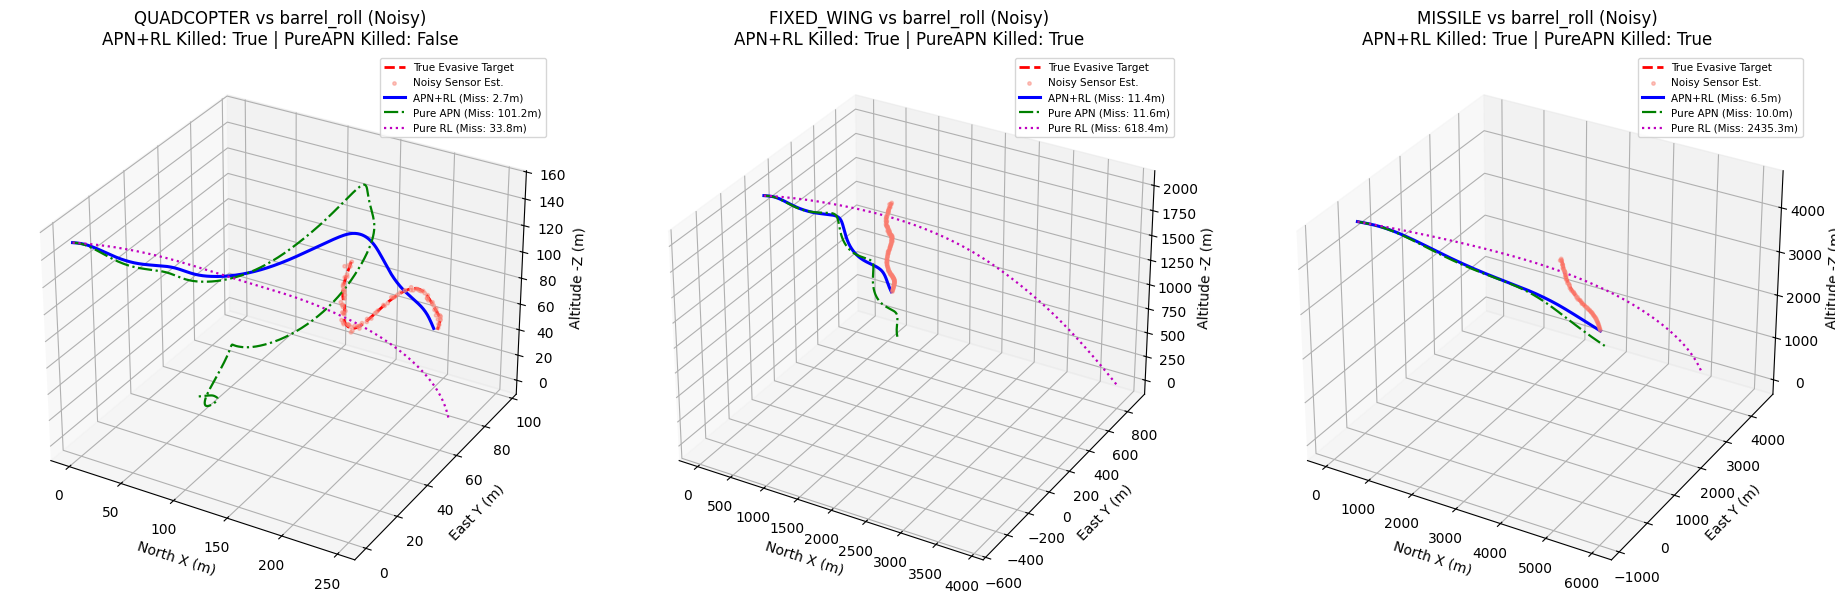

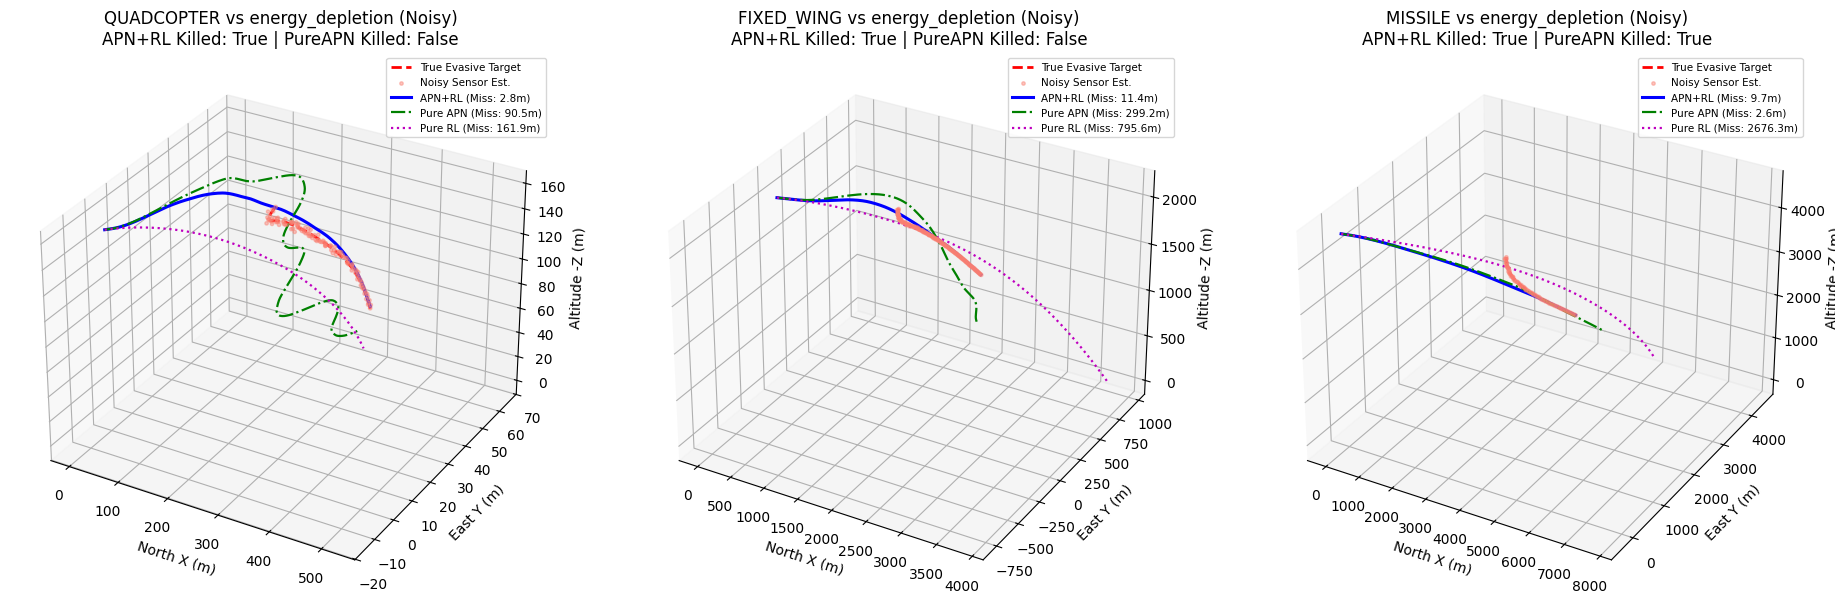

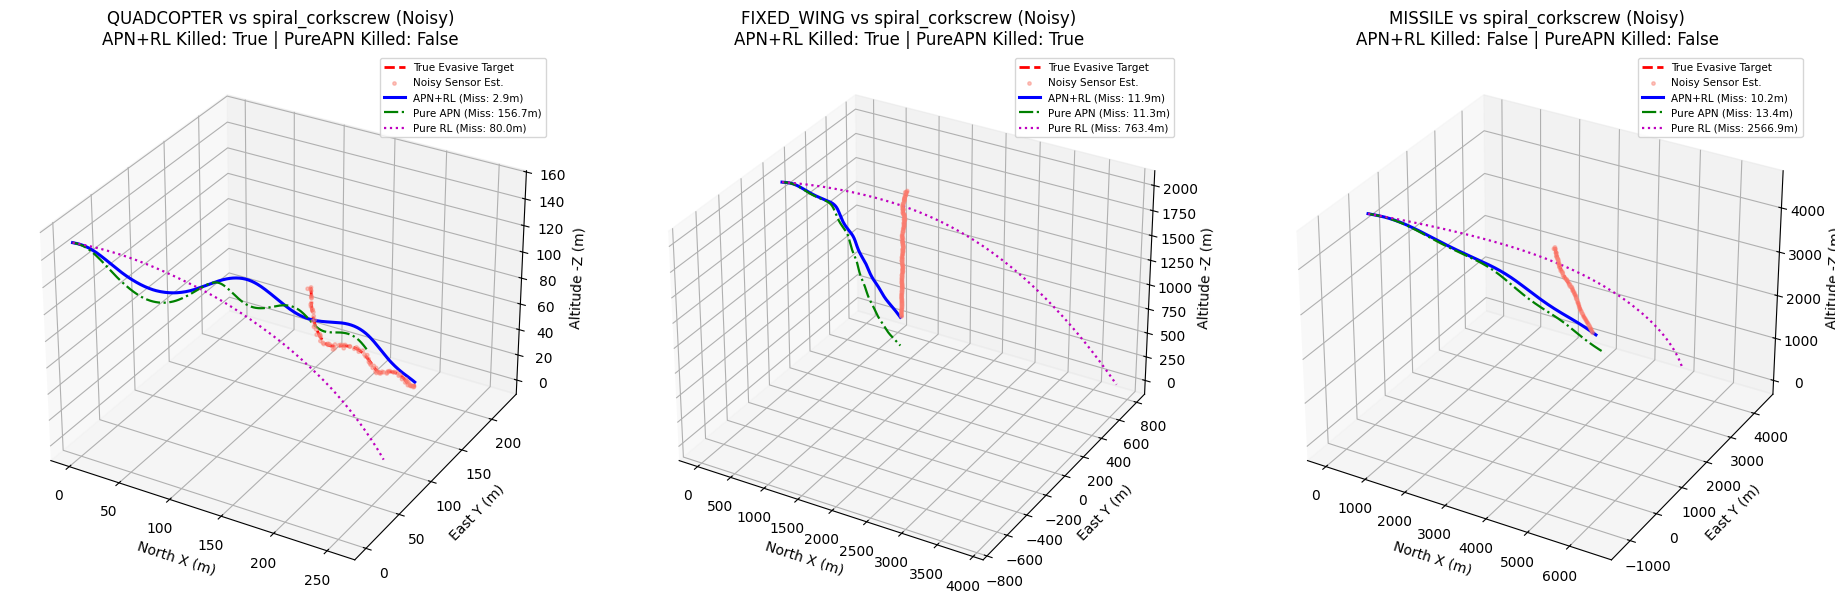

In [9]:
def plot_three_way_3d_trajectories(
    apn_rl_models: Dict[PlatformType, PPO],
    pure_rl_models: Dict[PlatformType, PPO],
    maneuver: ManeuverType = ManeuverType.BARREL_ROLL,
    noise_scale: float = 1.0,
):
    fig = plt.figure(figsize=(19, 6))
    for idx, platform in enumerate([PlatformType.QUADCOPTER, PlatformType.FIXED_WING, PlatformType.MISSILE], 1):
        seed_plot = 2026

        # 1. APN + RL rollout
        env_ar = NoisyInterceptorPathPlanningEnv(
            platform=platform, use_apn=True, pure_apn_mode=False,
            noise_scale=noise_scale, fixed_maneuver=maneuver, seed=seed_plot
        )
        obs, _ = env_ar.reset()
        done = False
        while not done:
            act, _ = apn_rl_models[platform].predict(obs, deterministic=True)
            obs, _, term, trunc, info_ar = env_ar.step(act)
            done = term or trunc

        # 2. Pure RL rollout
        env_pr = NoisyInterceptorPathPlanningEnv(
            platform=platform, use_apn=False, pure_apn_mode=False,
            noise_scale=noise_scale, fixed_maneuver=maneuver, seed=seed_plot
        )
        obs, _ = env_pr.reset()
        done = False
        while not done:
            act, _ = pure_rl_models[platform].predict(obs, deterministic=True)
            obs, _, term, trunc, info_pr = env_pr.step(act)
            done = term or trunc

        # 3. Classical Pure APN rollout
        env_pa = NoisyInterceptorPathPlanningEnv(
            platform=platform, use_apn=True, pure_apn_mode=True,
            noise_scale=noise_scale, fixed_maneuver=maneuver, seed=seed_plot
        )
        env_pa.reset()
        done = False
        while not done:
            _, _, term, trunc, info_pa = env_pa.step(np.zeros(3, dtype=np.float32))
            done = term or trunc

        t_true = np.array(env_ar.traj_T)
        t_noisy = np.array(env_ar.traj_T_noisy)
        m_ar = np.array(env_ar.traj_M)
        m_pr = np.array(env_pr.traj_M)
        m_pa = np.array(env_pa.traj_M)

        ax = fig.add_subplot(1, 3, idx, projection="3d")
        ax.plot(t_true[:, 0], t_true[:, 1], -t_true[:, 2], "r--", lw=2.0, label="True Evasive Target")
        ax.scatter(t_noisy[::4, 0], t_noisy[::4, 1], -t_noisy[::4, 2], c="salmon", s=6, alpha=0.45, label="Noisy Sensor Est.")
        ax.plot(m_ar[:, 0], m_ar[:, 1], -m_ar[:, 2], "b-", lw=2.2, label=f"APN+RL (Miss: {info_ar['miss_distance']:.1f}m)")
        ax.plot(m_pa[:, 0], m_pa[:, 1], -m_pa[:, 2], "g-.", lw=1.6, label=f"Pure APN (Miss: {info_pa['miss_distance']:.1f}m)")
        ax.plot(m_pr[:, 0], m_pr[:, 1], -m_pr[:, 2], "m:", lw=1.6, label=f"Pure RL (Miss: {info_pr['miss_distance']:.1f}m)")

        ax.set_title(
            f"{platform.value.upper()} vs {maneuver.value} (Noisy)\n"
            f"APN+RL Killed: {info_ar['killed']} | PureAPN Killed: {info_pa['killed']}"
        )
        ax.set_xlabel("North X (m)")
        ax.set_ylabel("East Y (m)")
        ax.set_zlabel("Altitude -Z (m)")
        ax.legend(loc="best", fontsize=7.5)

    plt.tight_layout()
    plt.show()


plot_three_way_3d_trajectories(apn_rl_models, pure_rl_models, ManeuverType.BARREL_ROLL, noise_scale=1.0)
plot_three_way_3d_trajectories(apn_rl_models, pure_rl_models, ManeuverType.ENERGY_DEPLETION, noise_scale=1.0)
plot_three_way_3d_trajectories(apn_rl_models, pure_rl_models, ManeuverType.SPIRAL_CORKSCREW, noise_scale=1.0)
